# 2026-06-26 — New genome (8-5-2) comparison

The newest sequenced isolate **8-5-2** (order `B9TF7H`, *Pseudomonas_E* sp013179515) was just added
to `data/bacteria_genome/`. This notebook places it next to our three existing isolates
(**9-2-1**, **9-6-2**, **10-10-2**) in three parts:

1. **Strain panel — genome summary (Table 1)** — MRA-style table of genome / assembly / annotation
   metrics for all four isolates, read straight from the sequencing deliverables.
2. **Whole-genome similarity** — all-vs-all **ANI** (pyfastani) across the 4 assemblies.
3. **Surface-receptor overlap** — cluster the four strains' phage-receptor protein sets
   (the canonical *fresh* set from `receptor_fasta.py`, 89 / 89 / 86 / 86) and report shared vs
   unique receptors as a **numeric table** plus a **3-set Venn** (the near-identical 9-2-1 / 9-6-2
   clones are collapsed into one clade, as in `0617_receptor_venn`).

Run from `code/` (the repo's notebook cwd). Outputs → `output/0626_genome_comparison/`.

## Part 1 — Strain panel: genome summary (Table 1)

MRA-style summary of the four sequenced isolates — every value is read directly from each strain's
Bakta annotation summary, ONT assembly stats, CheckM, and sourmash outputs. Metrics are rows;
strains are columns (8-5-2 first).

*Bakta v1.12.0 annotation; Oxford Nanopore long-read assembly. Genome (GenBank) and raw-read (SRA) accessions are listed as \u201cpending\u201d \u2014 genomes not yet deposited.*

In [1]:
# ---- Table 1: per-strain genome / assembly / annotation summary ----
import glob
from pathlib import Path
import pandas as pd

OUT = Path("output/0626_genome_comparison"); OUT.mkdir(parents=True, exist_ok=True)

STRAIN_DIR = {   # 8-5-2 first = subject of interest
    "8-5-2":   "../data/bacteria_genome/8-5-2",
    "9-2-1":   "../data/bacteria_genome/9-2-1",
    "9-6-2":   "../data/bacteria_genome/9-6-2/rerun_QB9Y48",
    "10-10-2": "../data/bacteria_genome/10-10-2",
    "8-10-2":  "../data/bacteria_genome/8-10-2",
}

def _one(d, pat):
    g = glob.glob(f"{d}/{pat}")
    assert g, f"no file matches {d}/{pat}"
    return g[0]

def parse_bakta_txt(path):          # "Key: value" lines (Length, GC, CDSs, Software, ...)
    d = {}
    for line in Path(path).read_text().splitlines():
        if ":" in line:
            k, v = line.split(":", 1)
            d[k.strip()] = v.strip()
    return d

def parse_kv_tsv(path):             # two-column key/value TSV (*_ont-stats.tsv)
    out = {}
    for line in Path(path).read_text().splitlines():
        p = line.rstrip("\n").split("\t")
        if len(p) >= 2:
            out[p[0]] = p[1]
    return out

def parse_header_tsv(path):         # header + single data row (*_checkm-results.tsv)
    rows = Path(path).read_text().splitlines()
    return dict(zip(rows[0].split("\t"), rows[1].split("\t")))

def parse_sourmash(path):           # GTDB lineage + ANI
    rows = Path(path).read_text().splitlines()
    r = dict(zip(rows[0].split(","), rows[1].split(",")))
    return r["lineage"].split(";s__")[-1], float(r["query_ani_at_rank"])

def topology(path):                 # *_prepolished-assembly-info.yaml
    t = Path(path).read_text()
    return "Circular" if "topology: circular" in t else ("Linear" if "topology:" in t else "—")

SITE_META = {   # field metadata recorded on site, keyed by site group (first token of the isolate code)
    "8":  {"coords": "34°6'54\"N 117°43'28\"W", "elev": "410", "plant": "Chilopsis linearis"},
    "9":  {"coords": "34°6'54\"N 117°43'28\"W", "elev": "410", "plant": "Aesculus californica"},
    "10": {"coords": "34°6'52\"N 117°43'13\"W", "elev": "410", "plant": "Nicotiana quadrivalvis"},
}

def collect(d):
    bak = parse_bakta_txt(_one(d, "annotation/*_reference.txt"))
    ont = parse_kv_tsv(_one(d, "*_ont-stats.tsv"))
    chk = parse_header_tsv(_one(d, "*_checkm-results.tsv"))
    sp, ani = parse_sourmash(_one(d, "*_sourmash-genome-species.csv"))
    sample_id = Path(_one(d, "*_ont-stats.tsv")).name.replace("_ont-stats.tsv", "")
    total_genes = sum(int(bak[k]) for k in ["CDSs", "tRNAs", "tmRNAs", "rRNAs", "ncRNAs"])
    iso  = Path(d).name if Path(d).name != "rerun_QB9Y48" else Path(d).parent.name
    meta = SITE_META[iso.split("-")[0]]
    return {
        "Isolate (internal name)":     iso,
        "Sequencing sample ID":        sample_id,
        "Genome accession (GenBank)":  "pending",
        "Raw read accession (SRA)":    "pending",
        "Isolation source":            "California Botanic Garden soil",
        "Coordinates":                 meta["coords"],
        "Elevation (m)":               meta["elev"],
        "Adjacent plant":              meta["plant"],
        "Sequencing platform":         "Oxford Nanopore (long-read)",
        "Genome size (bp)":            f"{int(bak['Length']):,}",
        "Contigs (n)":                 bak["Count"],
        "Topology":                    topology(_one(d, "*_prepolished-assembly-info.yaml")),
        "N50 (bp)":                    f"{int(bak['N50']):,}",
        "GC content (%)":              bak["GC"],
        "Sequencing depth (\u00d7)":       f"{float(ont['est_cov']):.0f}",
        "Total reads":                 f"{int(ont['total_num_reads']):,}",
        "Read N50 (bp)":               f"{int(float(ont['rN50'])):,}",
        "Median read length (bp)":     f"{int(float(ont['median_read'])):,}",
        "Median read quality (Phred)": ont["median_phred"],
        "Completeness % (CheckM)":     chk["Completeness"],
        "Contamination % (CheckM)":    chk["Contamination"],
        "Closest species (GTDB)":      sp,
        "ANI to closest (%)":          f"{ani * 100:.2f}",
        "Total genes":                 f"{total_genes:,}",
        "CDS (protein-coding genes)":  f"{int(bak['CDSs']):,}",
        "tRNA":                        bak["tRNAs"],
        "rRNA":                        bak["rRNAs"],
        "ncRNA":                       bak["ncRNAs"],
        "Pseudogenes":                 bak["pseudogenes"],
        "Hypothetical proteins":       bak["hypotheticals"],
        "Coding density (%)":          bak["coding density"],
    }

ORDER = ["8-5-2", "9-2-1", "9-6-2", "10-10-2", "8-10-2"]
records = {s: collect(STRAIN_DIR[s]) for s in ORDER}
table1 = pd.DataFrame(records).reindex(list(records["8-5-2"].keys()))   # rows = metrics, cols = strains
table1.index.name = "Metric"
table1.to_csv(OUT / "table1_genome_summary.csv")
table1

,8-5-2,9-2-1,9-6-2,10-10-2,8-10-2
Metric,,,,,
Isolate (internal name),8-5-2,9-2-1,9-6-2,10-10-2,8-10-2
Sequencing sample ID,B9TF7H_1_Sample_1_8A,XH254M_1_sample_1,QB9Y48_1_rerun_sample_2_2,XH254M_3_sample_3,CZJZZ4_1_rerun_Sample_2_8B_2
Genome accession (GenBank),pending,pending,pending,pending,pending
Raw read accession (SRA),pending,pending,pending,pending,pending
Isolation source,California Botanic Garden soil,California Botanic Garden soil,California Botanic Garden soil,California Botanic Garden soil,California Botanic Garden soil
Coordinates,"34°6'54""N 117°43'28""W","34°6'54""N 117°43'28""W","34°6'54""N 117°43'28""W","34°6'52""N 117°43'13""W","34°6'54""N 117°43'28""W"
Elevation (m),410,410,410,410,410
Adjacent plant,Chilopsis linearis,Aesculus californica,Aesculus californica,Nicotiana quadrivalvis,Chilopsis linearis
Sequencing platform,Oxford Nanopore (long-read),Oxford Nanopore (long-read),Oxford Nanopore (long-read),Oxford Nanopore (long-read),Oxford Nanopore (long-read)


### Variable definitions & provenance

Companion data dictionary for Table 1: what each metric means and exactly where it comes from.
Everything is parsed from the sequencing facility's per-strain deliverable files (no manual entry
except the isolate name, isolation source, and the not-yet-assigned accessions). Saved as
`table1_genome_summary_documented.csv` (values + Description + Source in one file) for sharing.

In [2]:
# ---- documented version of Table 1 (values + definition + source) ----
# (description, "source file -> field / how derived") keyed by the exact Table 1 metric labels
DOC = {
    "Isolate (internal name)":     ("Our lab's site code for the isolate.", "strain folder name under data/bacteria_genome/"),
    "Sequencing sample ID":        ("Sequencing facility's order/sample identifier.", "deliverable filename prefix (*_ont-stats.tsv)"),
    "Genome accession (GenBank)":  ("NCBI GenBank assembly accession (after deposition).", "placeholder 'pending' - not yet deposited"),
    "Raw read accession (SRA)":    ("NCBI SRA accession for the raw reads (after deposition).", "placeholder 'pending' - not yet deposited"),
    "Isolation source":            ("Where the bacterium was isolated from.", "project metadata (soil, California Botanic Garden)"),
    "Coordinates":                 ("GPS coordinates of the sampling site.", "field metadata (recorded on site)"),
    "Elevation (m)":               ("Elevation of the sampling site, in meters.", "field metadata (recorded on site)"),
    "Adjacent plant":              ("Nearest plant at the sampling site.", "field metadata (recorded on site)"),
    "Sequencing platform":         ("Sequencing technology used.", "inferred from ONT deliverable files (*_ont-*)"),
    "Genome size (bp)":            ("Total assembled genome length, base pairs.", "annotation/*_reference.txt -> Length"),
    "Contigs (n)":                 ("Number of assembled sequences (1 = complete chromosome).", "*_reference.txt -> Count"),
    "Topology":                    ("Whether the chromosome closed into a circle.", "*_prepolished-assembly-info.yaml -> topology"),
    "N50 (bp)":                    ("Assembly N50 (= genome length for a single contig).", "*_reference.txt -> N50"),
    "GC content (%)":              ("Percent of bases that are G or C.", "*_reference.txt -> GC"),
    "Sequencing depth (×)":        ("Mean fold coverage of the genome by reads (polished).", "*_ont-stats.tsv -> est_cov"),
    "Total reads":                 ("Number of sequencing reads generated.", "*_ont-stats.tsv -> total_num_reads"),
    "Read N50 (bp)":               ("Read-length N50 (50% of bases in reads this long or longer).", "*_ont-stats.tsv -> rN50"),
    "Median read length (bp)":     ("Median length of the reads.", "*_ont-stats.tsv -> median_read"),
    "Median read quality (Phred)": ("Median per-read Phred quality score.", "*_ont-stats.tsv -> median_phred"),
    "Completeness % (CheckM)":     ("Estimated genome completeness from single-copy marker genes.", "*_checkm-results.tsv -> Completeness"),
    "Contamination % (CheckM)":    ("Estimated contamination from duplicated markers.", "*_checkm-results.tsv -> Contamination"),
    "Closest species (GTDB)":      ("Closest GTDB species assignment.", "*_sourmash-genome-species.csv -> lineage (species)"),
    "ANI to closest (%)":          ("Average nucleotide identity to that species representative.", "*_sourmash-genome-species.csv -> query_ani_at_rank x100"),
    "Total genes":                 ("All annotated genes (CDS + tRNA + tmRNA + rRNA + ncRNA).", "computed from *_reference.txt counts"),
    "CDS (protein-coding genes)":  ("Number of protein-coding genes.", "*_reference.txt -> CDSs"),
    "tRNA":                        ("Number of tRNA genes.", "*_reference.txt -> tRNAs"),
    "rRNA":                        ("Number of rRNA genes (5S/16S/23S).", "*_reference.txt -> rRNAs"),
    "ncRNA":                       ("Number of other non-coding RNA genes.", "*_reference.txt -> ncRNAs"),
    "Pseudogenes":                 ("Genes annotated as pseudogenes (disrupted/non-functional).", "*_reference.txt -> pseudogenes"),
    "Hypothetical proteins":       ("CDS with no known/assigned function.", "*_reference.txt -> hypotheticals"),
    "Coding density (%)":          ("Percent of the genome that is protein-coding.", "*_reference.txt -> coding density"),
}
assert set(DOC) == set(table1.index), set(table1.index) ^ set(DOC)

documented = table1.copy()
documented["Description"]          = [DOC[m][0] for m in table1.index]
documented["Source (file -> field)"] = [DOC[m][1] for m in table1.index]
documented.to_csv(OUT / "table1_genome_summary_documented.csv")
print("wrote", OUT / "table1_genome_summary_documented.csv")
documented[["Description", "Source (file -> field)"]]

wrote output/0626_genome_comparison/table1_genome_summary_documented.csv


,Description,Source (file -> field)
Metric,,
Isolate (internal name),Our lab's site code for the isolate.,strain folder name under data/bacteria_genome/
Sequencing sample ID,Sequencing facility's order/sample identifier.,deliverable filename prefix (*_ont-stats.tsv)
Genome accession (GenBank),NCBI GenBank assembly accession (after deposit...,placeholder 'pending' - not yet deposited
Raw read accession (SRA),NCBI SRA accession for the raw reads (after de...,placeholder 'pending' - not yet deposited
Isolation source,Where the bacterium was isolated from.,"project metadata (soil, California Botanic Gar..."
Coordinates,GPS coordinates of the sampling site.,field metadata (recorded on site)
Elevation (m),"Elevation of the sampling site, in meters.",field metadata (recorded on site)
Adjacent plant,Nearest plant at the sampling site.,field metadata (recorded on site)
Sequencing platform,Sequencing technology used.,inferred from ONT deliverable files (*_ont-*)


In [3]:
import os, re, shutil, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---- strains & paths (cwd = code/) ------------------------------------------
STRAINS = ["8-5-2", "9-2-1", "9-6-2", "10-10-2", "8-10-2"]   # last = P. capeferrum (different species)

GENOMES = {   # assembled genome FASTA per strain
    "8-5-2":   "../data/bacteria_genome/8-5-2/B9TF7H_1_Sample_1_8A_1_reference.fasta",
    "9-2-1":   "../data/bacteria_genome/9-2-1/XH254M_1_sample_1_1_reference.fasta",
    "9-6-2":   "../data/bacteria_genome/9-6-2/rerun_QB9Y48/QB9Y48_1_rerun_sample_2_2_1_reference.fasta",
    "10-10-2": "../data/bacteria_genome/10-10-2/XH254M_3_sample_3_1_reference.fasta",
    "8-10-2":  "../data/bacteria_genome/8-10-2/CZJZZ4_1_rerun_Sample_2_8B_2_1_reference.fasta",
}
RECEPTORS = {  # fresh receptor protein FASTA per strain (from receptor_fasta.py)
    s: f"0623_metagenome_rbp/out_receptor_fasta/{s}_receptors.faa" for s in STRAINS
}

OUT = Path("output/0626_genome_comparison"); OUT.mkdir(parents=True, exist_ok=True)
MMSEQS = shutil.which("mmseqs") or "/opt/homebrew/bin/mmseqs"

def read_fasta(path):
    name, seq = None, []
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            if name is not None: yield name, "".join(seq)
            name, seq = line[1:], []
        else:
            seq.append(line.strip())
    if name is not None: yield name, "".join(seq)

for s in STRAINS:
    assert Path(GENOMES[s]).exists(), GENOMES[s]
    assert Path(RECEPTORS[s]).exists(), RECEPTORS[s]
print("mmseqs:", MMSEQS)
print("receptors per strain:", {s: sum(1 for _ in read_fasta(RECEPTORS[s])) for s in STRAINS})

mmseqs: /opt/homebrew/bin/mmseqs
receptors per strain: {'8-5-2': 86, '9-2-1': 89, '9-6-2': 89, '10-10-2': 86, '8-10-2': 91}


## Part 2 — Whole-genome similarity (ANI)

FastANI (via `pyfastani`) over the five complete assemblies. ANI is directional, so we query every
genome against every genome and report the full 5×5 matrix. Values are left blank below FastANI's
~80 % floor — expected for **8-10-2**, a different species (*P. capeferrum*) that may fall below the
floor against the four *sp013179515* isolates.

In [4]:
import pyfastani

# build one sketch holding all 4 draft genomes, then query each against it
sk = pyfastani.Sketch()
contigs = {s: [seq.encode() for _, seq in read_fasta(GENOMES[s])] for s in STRAINS}
for s in STRAINS:
    sk.add_draft(s, contigs[s])
mapper = sk.index()

rows = []
for q in STRAINS:
    hits = {h.name: round(h.identity, 3) for h in mapper.query_draft(contigs[q])}
    rows.append({"query": q, **{r: hits.get(r) for r in STRAINS}})
ani = pd.DataFrame(rows).set_index("query").reindex(index=STRAINS, columns=STRAINS)
ani.to_csv(OUT / "ani_matrix.csv")
ani

,8-5-2,9-2-1,9-6-2,10-10-2,8-10-2
query,,,,,
8-5-2,100.000,99.380,99.380,99.996,87.435
9-2-1,99.420,100.000,100.000,99.404,87.534
9-6-2,99.420,100.000,100.000,99.404,87.529
10-10-2,99.997,99.396,99.396,100.000,87.654
8-10-2,87.656,87.623,87.623,87.651,100.000


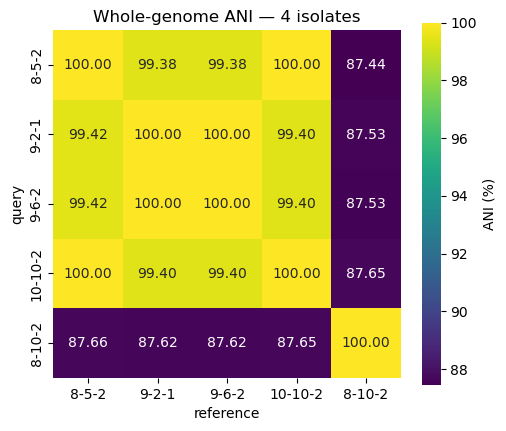

8-5-2 ANI to others:
  vs 9-2-1   : 99.38%  (near-identical clone)
  vs 9-6-2   : 99.38%  (near-identical clone)
  vs 10-10-2 : 100.00%  (near-identical clone)
  vs 8-10-2  : 87.44%  (distinct)


In [5]:
# ANI heatmap
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(ani.astype(float), annot=True, fmt=".2f", cmap="viridis",
            vmin=float(np.nanmin(ani.values)), vmax=100, square=True,
            cbar_kws={"label": "ANI (%)"}, ax=ax)
ax.set_title("Whole-genome ANI — 4 isolates")
ax.set_xlabel("reference"); ax.set_ylabel("query")
plt.tight_layout(); plt.savefig(OUT / "ani_heatmap.png", dpi=150); plt.show()

# 8-5-2 vs the rest
row = ani.loc["8-5-2"].drop("8-5-2").astype(float)
print("8-5-2 ANI to others:")
for s, v in row.items():
    tag = "near-identical clone" if v >= 99.0 else ("same strain-cluster" if v >= 97 else "distinct")
    print(f"  vs {s:8s}: {v:.2f}%  ({tag})")

## Part 3 — Surface-receptor overlap

Pool the four strains' fresh receptor sets and cluster them with **MMseqs2 `easy-cluster`** at
**≥95 % identity & ≥80 % mutual coverage** (same "same-receptor" definition as `0617_receptor_venn`).
Each cluster = one receptor; a strain "has" that receptor if it contributes ≥1 member. Sequence IDs
are namespaced `strain|locus` so members map back unambiguously.

In [6]:
# combined receptor FASTA with namespaced ids: "strain|locus"
combined = OUT / "all_receptors.fasta"
strain_of = {}
with open(combined, "w") as out:
    for s in STRAINS:
        for name, seq in read_fasta(RECEPTORS[s]):
            locus = name.split()[0]
            sid = f"{s}|{locus}"
            strain_of[sid] = s
            out.write(f">{sid}\n{seq}\n")
print(f"{len(strain_of)} receptor sequences pooled across {len(STRAINS)} strains")

tmp = OUT / "mmseqs_tmp"
pref = OUT / "clust"
subprocess.run([MMSEQS, "easy-cluster", str(combined), str(pref), str(tmp),
                "--min-seq-id", "0.95", "-c", "0.80", "--cov-mode", "0", "-v", "1"],
               check=True, capture_output=True, text=True)

# parse cluster TSV: rep<tab>member  -> cluster -> {strains present}
members = {}
for line in open(f"{pref}_cluster.tsv"):
    rep, mem = line.rstrip("\n").split("\t")
    members.setdefault(rep, set()).add(mem)

# presence: strain -> set(cluster reps it appears in)
present = {s: set() for s in STRAINS}
for rep, mem_set in members.items():
    for s in {strain_of[m] for m in mem_set}:
        present[s].add(rep)
print(f"{len(members)} distinct receptor clusters total")

441 receptor sequences pooled across 5 strains


178 distinct receptor clusters total


In [7]:
# ---- numeric shared/unique table ----
clade_9x = present["9-2-1"] | present["9-6-2"]      # near-identical clones collapsed
core_all = set.intersection(*[present[s] for s in STRAINS])

tab = pd.DataFrame(index=STRAINS)
tab["receptors (raw)"]   = [sum(1 for _ in read_fasta(RECEPTORS[s])) for s in STRAINS]
tab["receptor clusters"] = [len(present[s]) for s in STRAINS]
tab["shared w/ 8-5-2"]   = [len(present[s] & present["8-5-2"]) for s in STRAINS]
tab["unique to strain"]  = [len(present[s] - set.union(*[present[o] for o in STRAINS if o != s])) for s in STRAINS]
tab["in core (all 5)"]   = [len(present[s] & core_all) for s in STRAINS]
tab.to_csv(OUT / "receptor_overlap_table.csv")
print(f"core receptors shared by all 5 strains: {len(core_all)}")
print(f"receptors unique to 8-5-2 (in no other strain): "
      f"{len(present['8-5-2'] - set.union(*[present[o] for o in STRAINS if o != '8-5-2']))}")
print(f"receptors unique to 8-10-2 (P. capeferrum, divergent species): "
      f"{len(present['8-10-2'] - set.union(*[present[o] for o in STRAINS if o != '8-10-2']))}")
tab

core receptors shared by all 5 strains: 12
receptors unique to 8-5-2 (in no other strain): 0
receptors unique to 8-10-2 (P. capeferrum, divergent species): 79


,receptors (raw),receptor clusters,shared w/ 8-5-2,unique to strain,in core (all 5)
8-5-2,86,86,86,0,12
9-2-1,89,89,76,0,12
9-6-2,89,89,76,0,12
10-10-2,86,86,86,0,12
8-10-2,91,91,12,79,12


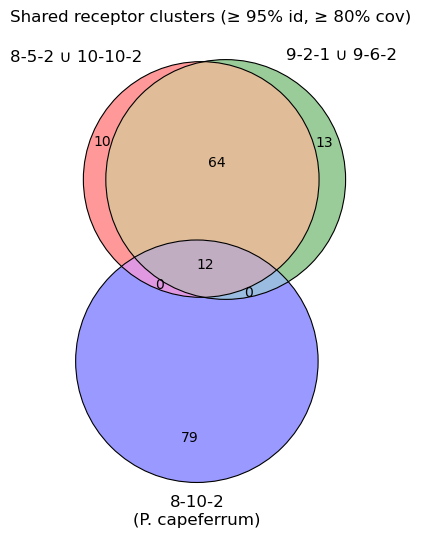

membership matrix: (178, 5)


In [8]:
# ---- 3-set Venn: the two sp013179515 strain clusters vs the new species (8-10-2) ----
from matplotlib_venn import venn3, venn3_circles

A = present["8-5-2"] | present["10-10-2"]   # sp013179515 cluster 1 (8-5-2 ≈ 10-10-2)
B = present["9-2-1"] | present["9-6-2"]      # sp013179515 cluster 2 (9-2-1 ≈ 9-6-2)
C = present["8-10-2"]                          # P. capeferrum (different species)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
v = venn3([A, B, C], set_labels=("8-5-2 \u222a 10-10-2", "9-2-1 \u222a 9-6-2", "8-10-2\n(P. capeferrum)"), ax=ax)
venn3_circles([A, B, C], lw=0.8, ax=ax)
ax.set_title("Shared receptor clusters (\u2265 95% id, \u2265 80% cov)")
plt.tight_layout(); plt.savefig(OUT / "receptor_venn.png", dpi=150); plt.show()

# membership CSV (cluster x strain presence) for the record
mem_df = pd.DataFrame(
    {s: [int(rep in present[s]) for rep in members] for s in STRAINS},
    index=list(members),
)
mem_df.index.name = "cluster_rep"
mem_df.to_csv(OUT / "receptor_cluster_membership.csv")
print("membership matrix:", mem_df.shape)

### Between-strain receptor identity

A receptor-level companion to the genome ANI: all-vs-all **MMseqs2 `easy-search`** over the pooled
receptors; for each ordered strain pair (A → B) we take the **median best-hit % identity** of A's
receptors against B. Diagonal ≈ 100 %.

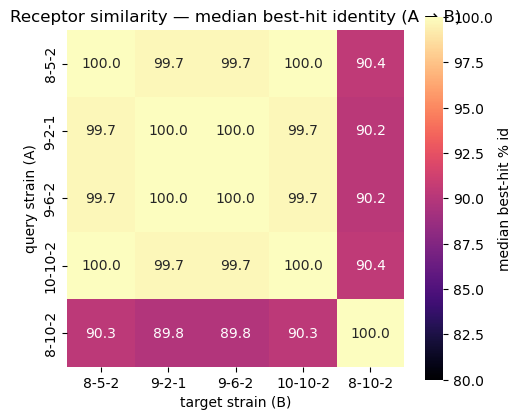

,8-5-2,9-2-1,9-6-2,10-10-2,8-10-2
8-5-2,100.0,99.7,99.7,100.0,90.4
9-2-1,99.7,100.0,100.0,99.7,90.2
9-6-2,99.7,100.0,100.0,99.7,90.2
10-10-2,100.0,99.7,99.7,100.0,90.4
8-10-2,90.3,89.8,89.8,90.3,100.0


In [9]:
res = OUT / "search.m8"
tmp2 = OUT / "mmseqs_tmp_search"
subprocess.run([MMSEQS, "easy-search", str(combined), str(combined), str(res), str(tmp2),
                "-s", "7.5", "-e", "1e-3", "--max-seqs", "2000",
                "--format-output", "query,target,fident", "-v", "1"],
               check=True, capture_output=True, text=True)

# best hit of each query receptor into each strain (exclude self-hit, same id)
best = {}   # (strainA, sid_query, strainB) -> max fident
for line in open(res):
    q, t, fident = line.rstrip("\n").split("\t")
    if q == t:
        continue
    sa, sb, f = strain_of[q], strain_of[t], float(fident)
    k = (sa, q, sb)
    if f > best.get(k, 0.0):
        best[k] = f

mat = pd.DataFrame(index=STRAINS, columns=STRAINS, dtype=float)
for sa in STRAINS:
    for sb in STRAINS:
        if sa == sb:
            mat.loc[sa, sb] = 100.0; continue
        vals = [v for (a, q, b), v in best.items() if a == sa and b == sb]
        mat.loc[sa, sb] = round(100.0 * np.median(vals), 2) if vals else np.nan
mat.to_csv(OUT / "receptor_identity_matrix.csv")

fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(mat.astype(float), annot=True, fmt=".1f", cmap="magma", vmin=80, vmax=100,
            square=True, cbar_kws={"label": "median best-hit % id"}, ax=ax)
ax.set_title("Receptor similarity — median best-hit identity (A \u2192 B)")
ax.set_xlabel("target strain (B)"); ax.set_ylabel("query strain (A)")
plt.tight_layout(); plt.savefig(OUT / "receptor_identity_heatmap.png", dpi=150); plt.show()
mat

## Summary

- **Genome ANI** (`ani_matrix.csv`, `ani_heatmap.png`) places the five isolates relative to one another; 8-10-2 is a different species (*P. capeferrum*).
- **Receptor overlap** (`receptor_overlap_table.csv`, `receptor_venn.png`) gives shared / unique /
  core receptor counts; the Venn groups the two *sp013179515* clusters (8-5-2∪10-10-2, 9-2-1∪9-6-2) against the new species 8-10-2.
- **Receptor identity** (`receptor_identity_matrix.csv`, `receptor_identity_heatmap.png`) — the
  protein-level analogue of ANI.

All outputs in `output/0626_genome_comparison/`.

---
*Log: 2026-06-26 — created. Genome ANI (pyfastani) + receptor overlap (MMseqs2 easy-cluster, ≥95% id / ≥80% cov) for the new isolate 8-5-2 vs 9-2-1 / 9-6-2 / 10-10-2. Receptor sets = fresh `receptor_fasta.py` output (8-5-2 added to its STRAINS dict).*
*Log: 2026-06-27 — added isolate **8-10-2** (order CZJZZ4, ***Pseudomonas_E capeferrum*** — a different species from the other four; complete genome, CheckM 100%/0.2%, 5.70 Mbp). Re-ran ANI (now 5×5), receptor overlap/identity (now 5 strains), and Table 1; receptor Venn regrouped into the two *sp013179515* clusters vs 8-10-2. Added 8-10-2 to `receptor_fasta.py` STRAINS (91 receptors).*